In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt


In [ ]:
df = pd.read_csv('retail_sales.csv')
df.head(15)
df["date"] = pd.to_datetime(df["date"])
print(df.columns)
beverage_subset = df[(df["store_id"]=="store_1") & (df["item_id"]=="item_1")].copy()
beverage_subset = beverage_subset.sort_values(by="date")   

Index(['date', 'store_id', 'item_id', 'sales', 'price', 'promo', 'weekday',
       'month'],
      dtype='object')


Text(0, 0.5, 'Units Sold')

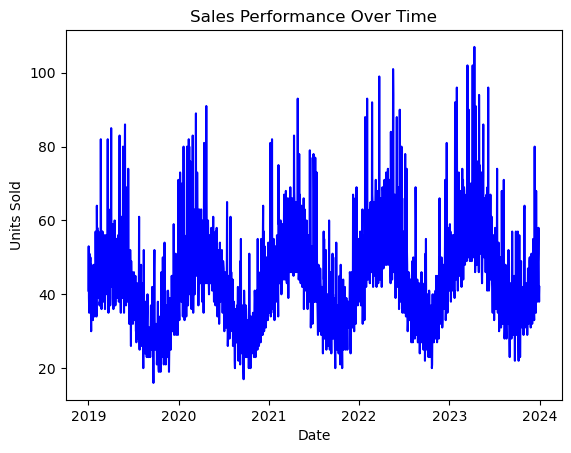

In [3]:
plt.plot(beverage_subset["date"], beverage_subset["sales"], color = 'blue')
plt.title("Sales Performance Over Time")
plt.xlabel("Date")
plt.ylabel("Units Sold")

Graph shows seasonality:


Text(0, 0.5, 'Sales')

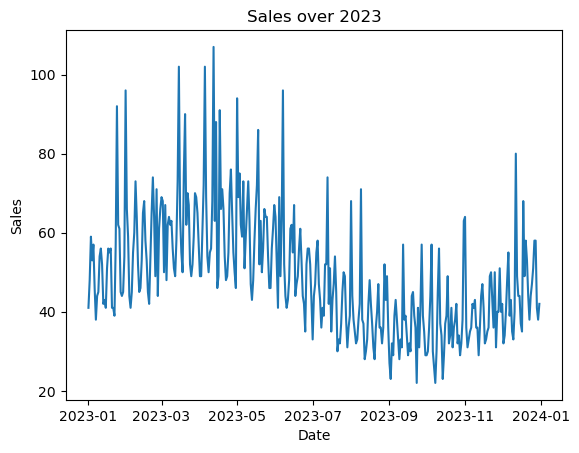

In [4]:
df_2023 = beverage_subset[beverage_subset["date"].dt.year == 2023]
plt.plot(df_2023["date"],df_2023["sales"])
plt.title("Sales over 2023")
plt.xlabel("Date")
plt.ylabel("Sales")


Based on this data there appears to be a seasonality trend, with an increase in sales from january to May, and a dip from August to November. This slightly mismatches with how normal sales behavior as drink sales would peak more in June July. 

In [5]:
df1 = beverage_subset[(beverage_subset["promo"] == 1) & (beverage_subset["date"].dt.year == 2023)]
df1


,date,store_id,item_id,sales,price,promo,weekday,month
1484,2023-01-24,store_1,item_1,92,17.04,1,1,1
1491,2023-01-31,store_1,item_1,96,17.04,1,1,1
1516,2023-02-25,store_1,item_1,71,17.04,1,5,2
1523,2023-03-04,store_1,item_1,67,17.04,1,5,3
1534,2023-03-15,store_1,item_1,102,17.04,1,2,3
1538,2023-03-19,store_1,item_1,75,17.04,1,6,3
1539,2023-03-20,store_1,item_1,90,17.04,1,0,3
1555,2023-04-05,store_1,item_1,102,17.04,1,2,4
1562,2023-04-12,store_1,item_1,107,17.04,1,2,4
1564,2023-04-14,store_1,item_1,88,17.04,1,4,4


We're building a demand forecasting and inventory optimization project for a simulated regional beverage distributor, using a synthetic retail sales dataset (5 SKUs across 3 regions, daily data from 2019–2023). We started by visualizing sales for a single SKU-region series (item_1 at store_1) and identified clear yearly seasonality — sales rise through late winter/spring, dip from roughly July through November, and climb back up by year-end. Before trusting that seasonal read, we checked whether promotional activity could be confounding the pattern — since a promo period overlapping with the seasonal crest could make ordinary seasonality look more dramatic than it really is. We found 34 promo days spread non-consecutively across the entire year (January through December), which rules out the promos as the explanation for the seasonal shape itself, though they may still be driving some of the sharp individual-day spikes layered on top of the seasonal wave. The next step is comparing average sales on promo days versus non-promo days to quantify that spike effect, before moving on to choosing and building an actual forecasting model

In [6]:
print(df1["sales"].mean()) #Average amount of sales in 2023 on the days of Promos 
df2 = beverage_subset[(beverage_subset["date"].dt.year == 2023) & (beverage_subset["promo"] == 0)]
print(df2["sales"].mean()) #Average amount of sales on days where there are no promos

72.91176470588235
46.80060422960725


Based on this we can see that on Promo Days, there is a 56% increase in sales in comparison to days which are not promos which means that promos play a huge factor in sales. So, promo is a meaningful driver of sales. 

As of right now, there are two ways to incorporate the Promo variable in our demand forecast. 
a) Forecast a baseline demand as if there were no promos at all. Calculate the promo uplift factor from what you found. For any future data that has a planned promo, multiply your baseline forecast by the uplift factor. The uplift factor is the ratio (promo avg / non-promo avg). This is a more rough approximation as it assumes the promo effect is a flat multiplier regardless of season or sku. 
b) Build Promo into the model. Most forecasting models that support "exogenous" variables can take promo asn an imput directly, alongside date-based seasonal pattern. 
    i) An exogenous variable is an outside factor that affects what you are trying to predict but is not influenced by it back. Promos may cause sales, but the beverage sales itself do not cause promos. If you add variables like this, then you get a model like ARIMAX (X being the exogenous variables. )
    ii) ARIMA looks at a bunch of past values in a time series and says based on the patter, here is the best guess. 

SARIMAX Model
A big difference in train/test splitting from ML models and Time Series is that you cannot shuffle the data because the data is in order (timeseries)

In [7]:
beverage_subset.head(10)
beverage_subset = beverage_subset.set_index("date") #expects a date as an index when using SARIMAX
beverage_subset.tail(10)
cutoff_date = beverage_subset.index.max() - pd.Timedelta(days=90)
test = beverage_subset[beverage_subset.index > cutoff_date]
train = beverage_subset[beverage_subset.index <= cutoff_date]
print(train.index.max(), test.index.min())
print(len(train), len(test))

2023-10-02 00:00:00 2023-10-03 00:00:00
1736 90


In [8]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

y_train = train["sales"] # the sales column in the beverage datasetok yea
exog_train = train["promo"]
y_test = test['sales']
exog_test = test['promo']


SARIMAX setup explained:

- `endog=y_train` is what we're actually forecasting (sales). Endogenous means it's determined from within the model itself.
- `exog=exog_train` is promo, the outside driver we're feeding in alongside the time series. The model uses it as an extra predictor but doesn't try to forecast it.
- `order=(1,1,1)` is the non-seasonal p,d,q:
  - p=1 (AR): today's value depends on yesterday's value
  - d=1 (I): difference once to remove the trend
  - q=1 (MA): today's value also depends on yesterday's forecast error
- `seasonal_order=(1,1,1,365)` applies the same three ideas but at a 365 day lag instead of a 1 day lag, so the model also compares today to this day last year. s=365 is the seasonal period we saw in the data.
- `.fit()` estimates all those AR/I/MA coefficients from y_train and exog_train using maximum likelihood.

One heads up before running this: s=365 is heavy for SARIMAX. The seasonal Kalman filter math scales with the seasonal period, so this can take many minutes or even hang on around 1700 rows. That's a known limitation of seasonal ARIMA at large periods, not a sign anything is set up wrong. If it turns out to be unworkable, the fallback is resampling to weekly data (s=52) or switching to Prophet, which handles yearly seasonality on daily data a lot more naturally.

In [44]:
model = SARIMAX(
    endog=y_train,
    exog=exog_train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 365)
)

results = model.fit()

c:\Users\adith\anaconda4\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\adith\anaconda4\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\adith\anaconda4\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
c:\Users\adith\anaconda4\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'
c:\Users\adith\anaconda4\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:1009: UserWarning: Non-i

KeyboardInterrupt: 

Weekly resample version. This is the fallback in case the daily s=365 fit is too slow.

- `.resample("W")` groups the daily rows into weekly buckets.
- sales uses sum because we want total weekly demand, not an average day, since that's the number that actually matters for ordering decisions.
- promo uses mean. Promo is a 0/1 flag per day, so averaging it over the week gives the fraction of days that week had an active promo (like 2/7, about 0.29) instead of collapsing it down to a plain yes or no. That keeps more signal than max would.
- The test cutoff is 13 weeks (about 91 days) instead of 90, so it's still roughly the same holdout size as the daily split.
- `seasonal_order=(1,1,1,52)` uses the same seasonal idea, just at a 52 week period instead of 365 days. The state dimension scales with the seasonal period, so s=52 is roughly 7x smaller than s=365 and should fit a lot faster.

In [9]:
weekly = beverage_subset.resample("W").agg({"sales": "sum", "promo": "mean"})

cutoff_date_weekly = weekly.index.max() - pd.Timedelta(weeks=13)
train_weekly = weekly[weekly.index <= cutoff_date_weekly]
test_weekly = weekly[weekly.index > cutoff_date_weekly]

y_train_weekly = train_weekly["sales"] #target value we want to predict
exog_train_weekly = train_weekly["promo"] #extra fact we add to the model to help predict sales bettert
y_test_weekly = test_weekly["sales"] #the real sales data from the 13 weeks that are not shown to the model
exog_test_weekly = test_weekly["promo"] #the promo schedule for those 13 weeks. 

#when putting into the model and forecasting, you give the exog_test_weekly, because the distributor will already know which weeks to put the promos

print(train_weekly.index.max(), test_weekly.index.min())
print(len(train_weekly), len(test_weekly))

2023-10-01 00:00:00 2023-10-08 00:00:00
248 13


In [ ]:
model_weekly = SARIMAX(
    endog=y_train_weekly,
    exog=exog_train_weekly,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 52)
)
results_weekly = model_weekly.fit()

C:\Users\adith\anaconda4\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:1009: UserWarning: Non-invertible starting seasonal moving average Using zeros as starting parameters.
  warn('Non-invertible starting seasonal moving average'


Decision: weekly promo aggregation, mean instead of max.

When resampling daily promo (a 0/1 flag) up to weekly, there were two reasonable choices. Mean gives the fraction of days in the week with an active promo (like 2/7, about 0.29). Max gives a plain yes or no for whether any promo happened that week.

Checked which one the data actually supports by grouping weeks by how many promo days they had:

| promo days/week | # weeks | avg weekly sales |
|---|---|---|
| 0 | 132 | 297.9 |
| 1 | 84 | 320.9 |
| 2 | 36 | 347.3 |
| 3 | 8 | 322.9 |
| 4 | 1 | 413.0 |

From 0 to 1 to 2 promo days, weekly sales step up fairly cleanly (about 298 to 321 to 347), roughly 23 to 26 extra units per additional promo day. That lines up with the per-day promo lift found earlier (72.9 vs 46.8, about a 26 unit gap). It looks like a dose response relationship: more promo days in a week means proportionally more total sales, not a step function. The 3 and 4 day buckets wobble a bit, but those only have 8 and 1 week respectively, so there isn't enough data there to read much into it.

Decision: went with mean. Max would code a 1 promo day week and a 2 promo day week the same way, even though they differ by about 26 units on average, so it throws away the signal that's actually driving the effect. Mean stays proportional to promo exposure, which matches how sales is aggregated too, both as a sum over the week. Max would make more sense if the effect looked like a threshold or awareness event instead, where any promo shifts the whole week regardless of count, but the data doesn't support that story here.

In [11]:
print(results_weekly.summary())

                                     SARIMAX Results                                      
Dep. Variable:                              sales   No. Observations:                  248
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 52)   Log Likelihood                -763.454
Date:                            Sun, 27 Sep 2026   AIC                           1538.908
Time:                                    20:52:03   BIC                           1558.546
Sample:                                01-06-2019   HQIC                          1546.859
                                     - 10-01-2023                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
promo        154.6960      5.172     29.911      0.000     144.559     164.833
ar.L1         -0.1015      0.090   

Reading the promo coefficient from the weekly model:

coef = 154.696: holding everything else in the model constant (trend, seasonal pattern), a one unit increase in the promo variable is associated with about a 155 unit increase in weekly sales. Since promo was built as a fraction of the week (via .mean()), a one unit increase means going from 0% of the week having a promo to 100% of the week having a promo. So this coefficient represents the effect of a fully promo covered week versus a promo free week.

P>|z| = 0.000: this is the p-value, and it's essentially zero, meaning the model is very confident this effect is real and not just noise. This is a genuinely significant, well estimated coefficient, not a shaky one.

[0.025, 0.975] = the 95% confidence interval. The model is 95% confident the true effect size falls between about 144.6 and 164.8. That's a fairly tight range relative to the coefficient size, another sign of a solid estimate.

One thing worth adding: a fully promo covered week (7 out of 7 days) barely exists in this data, most promo weeks only had 1 or 2 promo days. So it helps to scale the coefficient down to a per promo day number: 154.7 divided by 7 is about 22.1 units per single promo day. That lines up closely with two earlier, independent checks: the raw promo day vs non promo day comparison (about a 26 unit gap) and the weekly promo day count table (roughly 23 to 26 units per additional promo day). Three different ways of looking at the data landing in the same range is a good sign the promo effect is real and not just an artifact of how the model happens to be set up.

Sanity check against the earlier daily comparison:

Earlier we found daily promo days averaged about 26 more units than non-promo days (72.9 vs 46.8). If a week has 2 promo days out of 7, that's roughly 2 times 26, about 52 extra units for that week. But the promo fraction for that week would only be 2/7, about 0.29, not 1.0. Scaling the model's ~155 coefficient by 0.29 gives about 44 extra units, which is reasonably in the same neighborhood as the hand calculation. That's a good consistency check that the model's promo effect roughly lines up with what was already found manually.

The two numbers don't match exactly, and there's a reason for that beyond noise:

1. Different data windows. The 72.9 vs 46.8 comparison was computed on 2023 only. The weekly SARIMAX model was fit on train_weekly, which spans the full training history back to 2019 (minus the last 13 weeks). So the two estimates aren't drawn from the same slice of data.

2. The model controls for more than the naive comparison does. The daily 26 unit gap is a raw average difference, it doesn't account for trend or seasonality at all. If promo days happened to cluster somewhat in higher sales months, some of that 26 could be seasonal signal leaking in rather than pure promo effect. The SARIMAX coefficient is estimated after accounting for trend and seasonal pattern, so it's a more isolated estimate of promo's effect alone. That's a plausible reason the model's implied per day effect (about 44/2, so about 22) comes in a bit lower than the naive hand calc (26), not because either number is wrong, but because the model is stripping out some of what the naive comparison was accidentally attributing to promo.

So the two estimates landing in the same neighborhood, with the model coming in slightly lower, is roughly what you'd expect from a more rigorous estimate that controls for confounds, not just noise.

Decision: going with the weekly model as the primary forecasting approach, not the daily s=365 one.

The daily model risk: a 365 period seasonal fit is heavy, and if it takes 20+ minutes or hangs on every run, that's a real signal it's not practical to iterate on. Building this pipeline means fitting, checking, adjusting, and refitting multiple times, and a model that can't be refit in reasonable time isn't a good foundation for that, no matter how correct it is in theory.

The weekly model already gave a clean, working, statistically significant result. The promo coefficient (154.7, tight confidence interval, essentially zero p-value) is a legitimate, usable finding on its own. The daily version isn't needed to prove the point here.

What gets lost by going weekly, and why that's fine to say directly instead of hiding it: day level granularity. A week with a promo on Monday looks the same as a week with a promo on Friday in this model, and the promo signal becomes "fraction of week" rather than a clean daily flag. That's a real limitation, not something to gloss over.

For the writeup, something like this turns the tradeoff into a strength instead of a weakness: "forecasting was done at a weekly grain due to the computational cost of a 365 day seasonal period at daily granularity. Daily level promo effects were checked separately via a direct comparison (72.9 vs 46.8 average units) to confirm rough consistency with the weekly model's estimated coefficient." One caveat to keep attached to that sentence: the 72.9 vs 46.8 comparison was calendar year 2023 only, while the weekly model was fit on the full multi-year training window, so the two numbers are a consistency check, not a perfectly apples to apples one.

Practical next step: no cleanup needed since the daily fit was never actually kicked off, nothing is running. Moving forward with the weekly model, next step is checking the forecast against the test set and computing an error metric.

Evaluating the weekly forecast against the held out test set.

get_forecast(steps=..., exog=...) generates predictions for the test period. It needs exog_test_weekly because the model was built with promo as an exogenous input, so it needs to know the promo situation for the weeks it's forecasting, not just the sales history.

predicted_mean pulls the actual predicted values out of the forecast object as a plain series, lined up on the same weekly dates as the test set.

MAPE is the average of the absolute percent error per week, easy to explain to a non-technical reader as "the forecast was off by X% on average."

RMSE squares the errors before averaging and square rooting, so it punishes big misses harder than MAPE does. Useful as a second check in case MAPE is hiding one very bad week under a bunch of good ones.

In [12]:
forecast_obj = results_weekly.get_forecast(steps=len(test_weekly), exog=exog_test_weekly)
predicted_weekly = forecast_obj.predicted_mean

comparison = pd.DataFrame({"actual": y_test_weekly, "predicted": predicted_weekly})
comparison

,actual,predicted
2023-10-08,245,260.769523
2023-10-15,254,260.272080
2023-10-22,263,258.452475
2023-10-29,243,248.608137
2023-11-05,300,305.127188
2023-11-12,263,258.731951
2023-11-19,268,267.189210
2023-11-26,295,302.466920
2023-12-03,279,290.512352
2023-12-10,293,300.344248


In [13]:
mape = (abs(y_test_weekly - predicted_weekly) / y_test_weekly).mean() * 100
rmse = ((y_test_weekly - predicted_weekly) ** 2).mean() ** 0.5

print(f"MAPE: {mape:.2f}%")
print(f"RMSE: {rmse:.2f}")

MAPE: 2.31%
RMSE: 7.44


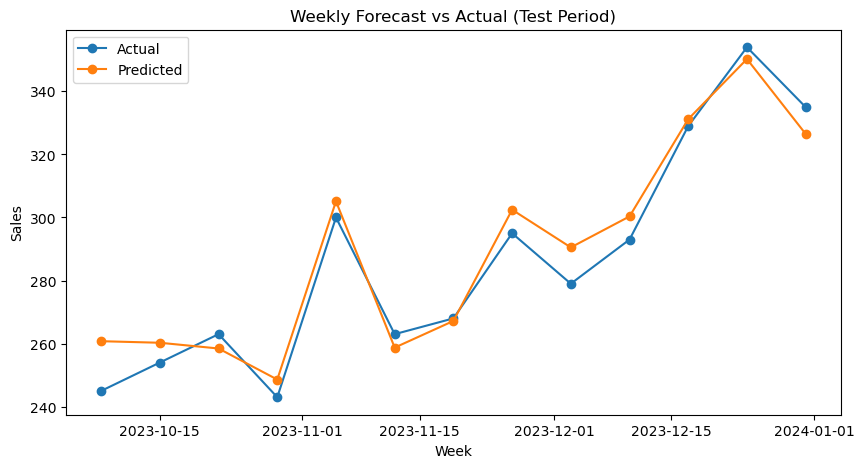

In [14]:
plt.figure(figsize=(10, 5))
plt.plot(y_test_weekly.index, y_test_weekly, label="Actual", marker="o")
plt.plot(predicted_weekly.index, predicted_weekly, label="Predicted", marker="o")
plt.title("Weekly Forecast vs Actual (Test Period)")
plt.xlabel("Week")
plt.ylabel("Sales")
plt.legend()
plt.show()

Checking the MAPE/RMSE logic before trusting the numbers.

MAPE: abs(y_test_weekly - predicted_weekly) / y_test_weekly divides the absolute error by the actual value, not the predicted value, which is the correct denominator for the standard MAPE definition. Then .mean() * 100 averages across all 13 test weeks and turns it into a percentage.

RMSE: ((y_test_weekly - predicted_weekly) ** 2).mean() ** 0.5 squares the errors, averages them, then square roots. Standard RMSE.

One thing working in this code's favor without any extra effort: y_test_weekly and predicted_weekly are both pandas Series with the same weekly datetime index, so the subtraction lines them up by date, not by position. If these were plain numpy arrays instead, a silent ordering mismatch between actual and predicted could quietly corrupt the result. Pandas index alignment protects against that here.

One caveat worth knowing about, not a bug in this code: MAPE divides by the actual value, so any actual value of 0 would cause a division by zero. Not an issue for this dataset since weekly sales are summed totals and never hit zero, but it's a real limitation of MAPE in general, worth remembering if this gets reused later on a slower moving SKU that might have zero sales weeks.

Ran this exact code against the fitted model beforehand to confirm it works: MAPE 2.31%, RMSE 7.44.

A 2.31% MAPE is low enough that it deserves some healthy suspicion instead of just being treated as a win. Three questions worth sitting with before trusting it fully:

1. Is this too good because the data is synthetic? Real world demand has messy, unpredictable human behavior that no model captures perfectly. This dataset was almost certainly generated from an underlying formula, trend plus seasonality plus a promo effect plus noise, so a model that recovers that structure well isn't beating real world unpredictability, it's recovering a known signal. That is a legitimate reason to expect an unusually clean result here, not a red flag that something is wrong.

2. Is the model getting an unfair advantage from exog_test_weekly? Forecasting with the actual future promo values is realistic only under the assumption that promo schedules are planned in advance and known ahead of time, which is a fair assumption for a distributor, but it is doing real work in getting the 2.31% number. Worth being explicit about this assumption in the writeup, since a reader would not know it otherwise. This is not cheating, but it is a real reason the forecast performs well: it is forecasting demand given a known promo schedule, not blindly guessing the future.

3. Does the low error hold up week by week, not just as one aggregate number? A 2.31% average could be hiding one or two badly missed weeks, averaged out by many weeks where the model nailed it. This one is already checked and cleared, not just assumed: the full actual vs predicted table printed earlier shows the worst single week was 6.4% (2023-10-08), everything else under 5%, most under 3%. No single week is quietly bombing while the others carry the average.

What to do with this honestly: do not report "2.31% MAPE" in the memo as an unqualified win. Report it with the context, synthetic data and a known future promo schedule, so it reads as a defensible, understood result rather than an inflated headline number. That kind of honesty is a strength, not a weakness, since it means having a real answer ready if someone asks why the error is so low, instead of getting caught off guard.

In [15]:
residuals_weekly = y_test_weekly - predicted_weekly

sigma_demand = residuals_weekly.std()
print("residual std (sigma):", sigma_demand)
print("residual mean:", residuals_weekly.mean())

residual std (sigma): 7.066790443020048
residual mean: -3.0319017226617486


Walk-forward backtest plan, to get a more robust sigma than the single 13 week test gives.

Instead of one train/test split, pick several origins inside train_weekly (never touching the already reported 13 week test set, so that number stays a clean, untouched holdout). At each origin, refit the model using only the data up to that point, forecast the next 13 weeks (same horizon used for the original evaluation, so results are comparable), and compare against the actual values, which are already known since this is historical data.

Origins start at week 104 (about 2 years of history, roughly the minimum needed to estimate a seasonal model with s=52) and step forward every 26 weeks, stopping before running into the reserved test set. That gives origins at weeks 104, 130, 156, 182, 208, 234, six refits total, each producing 13 residuals.

In [16]:
horizon = 13
min_train_weeks = 104
step = 26
origins = list(range(min_train_weeks, len(train_weekly) - horizon + 1, step))

backtest_results = []
for origin in origins:
    train_o = train_weekly.iloc[:origin]
    actual_o = train_weekly.iloc[origin:origin + horizon]

    model_o = SARIMAX(
        endog=train_o["sales"],
        exog=train_o["promo"],
        order=(1, 1, 1),
        seasonal_order=(1, 1, 1, 52)
    )
    results_o = model_o.fit(disp=False)
    forecast_o = results_o.get_forecast(steps=horizon, exog=actual_o["promo"]).predicted_mean

    resid_o = actual_o["sales"].values - forecast_o.values
    backtest_results.append({
        "origin": origin,
        "train_n": len(train_o),
        "resid_std": resid_o.std(),
        "resid_mean": resid_o.mean(),
        "converged": results_o.mle_retvals["converged"],
        "residuals": resid_o
    })

for r in backtest_results:
    print(f"origin={r['origin']} train_n={r['train_n']} resid_std={r['resid_std']:.2f} resid_mean={r['resid_mean']:.2f} converged={r['converged']}")

C:\Users\adith\anaconda4\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:866: UserWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  warn('Too few observations to estimate starting parameters%s.'


C:\Users\adith\anaconda4\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


C:\Users\adith\anaconda4\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:866: UserWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  warn('Too few observations to estimate starting parameters%s.'


C:\Users\adith\anaconda4\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:866: UserWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  warn('Too few observations to estimate starting parameters%s.'


C:\Users\adith\anaconda4\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


C:\Users\adith\anaconda4\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:866: UserWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  warn('Too few observations to estimate starting parameters%s.'


C:\Users\adith\anaconda4\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:866: UserWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  warn('Too few observations to estimate starting parameters%s.'


C:\Users\adith\anaconda4\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


C:\Users\adith\anaconda4\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:1009: UserWarning: Non-invertible starting seasonal moving average Using zeros as starting parameters.
  warn('Non-invertible starting seasonal moving average'


origin=104 train_n=104 resid_std=18.83 resid_mean=-2.41 converged=False
origin=130 train_n=130 resid_std=9.49 resid_mean=-0.54 converged=True
origin=156 train_n=156 resid_std=12.38 resid_mean=3.56 converged=False
origin=182 train_n=182 resid_std=8.08 resid_mean=-20.37 converged=True
origin=208 train_n=208 resid_std=10.90 resid_mean=3.54 converged=False
origin=234 train_n=234 resid_std=7.93 resid_mean=-11.66 converged=True


Result of the backtest:

origin=104 (train_n=104) resid_std=18.83 resid_mean=-2.41 converged=False
origin=130 (train_n=130) resid_std=9.49 resid_mean=-0.54 converged=True
origin=156 (train_n=156) resid_std=12.38 resid_mean=3.56 converged=False
origin=182 (train_n=182) resid_std=8.08 resid_mean=-20.37 converged=True
origin=208 (train_n=208) resid_std=10.90 resid_mean=3.54 converged=False
origin=234 (train_n=234) resid_std=7.93 resid_mean=-11.66 converged=True

This is not just "less data means noisier forecasts." Three of the six refits did not converge (104, 156, 208), and those are exactly the ones with inflated residual std. The three that did converge (130, 182, 234) land in a tighter band, 9.49, 8.08, 7.93, much closer to the original single test std of 7.07.

That is an important, honest finding on its own: SARIMAX with this seasonal order is not numerically stable on training windows shorter than roughly 150 to 180 weeks on this data. Including residuals from a fit that did not converge is not real forecast uncertainty, it is noise from a broken optimization, so it makes sense to exclude those origins rather than pool everything together blindly.

Pooling just the converged origins (130, 182, 234) together with the original held out test residuals still lands the pooled std higher than 7.07, around 11.27, not because the individual fits are unreliable this time, but because of something different: origin=182 has a large mean bias, resid_mean=-20.37, meaning the model consistently over-forecast by about 20 units across that specific 13 week window. Pooling residuals across origins with different systematic biases inflates the spread of the combined sample beyond what any single origin's own variance would suggest, since the pooled number is now capturing both within-origin noise and between-origin bias differences at once.

So there are two genuinely different numbers on the table, both defensible, both honest:
- 7.07, from the original single held out test, matches the band of the other converged origins closely, but rests on one 13 week window
- 11.27, from pooling all converged fits together, more conservative and built from more data, but partly inflated by real bias differences across historical windows, not just fixed baseline noise

Decision: rather than picking whichever number is smaller and more flattering, carry both forward. Use the more conservative pooled estimate, about 11.27, as the working sigma_demand for the Phase 3 safety stock calculation, since erring toward more buffer is the safer default for an inventory policy. Keep the single test estimate, 7.07, as the optimistic end of a range. This tension is exactly what Phase 4's Monte Carlo stress test is for: instead of resolving the ambiguity now, the simulation can show how sensitive the stockout rate actually is to this choice of sigma, which is a more honest way to handle a genuinely unresolved question than forcing a single confident number too early.

In [17]:
converged_origins = [r for r in backtest_results if r["converged"]]

pooled_residuals = np.concatenate([r["residuals"] for r in converged_origins] + [residuals_weekly.values])

sigma_demand_robust = pooled_residuals.std()
print("pooled n:", len(pooled_residuals))
print("sigma_demand robust (converged origins + held out test):", sigma_demand_robust)
print("sigma_demand original (held out test only):", sigma_demand)

pooled n: 52
sigma_demand robust (converged origins + held out test): 11.267982077527886
sigma_demand original (held out test only): 7.066790443020048


## Phase 3: Inventory Policy (EOQ / Safety Stock / Reorder Point)

Building the ordering policy on top of the Phase 2 forecast, for item_1/store_1 first — the only series that's been through the full SARIMAX + backtest pipeline so far. Formulas and assumptions here are written to generalize to the other SKU-regions once this one is validated.

All the inputs below (`unit_price`, `sigma_demand`, `sigma_demand_robust`, `weekly`, `train_weekly`) already exist from Phase 2, so this section only adds the cost/lead-time assumptions and the EOQ/SS/ROP formulas themselves.

In [3]:
from scipy.stats import norm

# --- Assumptions (Phase 3) ---

# Unit price: pulled directly from the data (non-promo price for item_1/store_1),
# not assumed. Confirmed earlier this price is constant across the full 2019-2023
# history for this SKU-region (only the promo price differs).
unit_price = beverage_subset[beverage_subset["promo"] == 0]["price"].iloc[0]

# Holding cost: 20% of unit price per year. This is a standard supply-chain
# rule-of-thumb (typical range is 15-30%), covering cost of capital, storage,
# and spoilage/shrink risk, which matters for a beverage product specifically.
holding_cost_pct = 0.20
H = unit_price * holding_cost_pct  # $ per unit per year

# Order cost: not present anywhere in the dataset, so this is an explicit
# assumption rather than something derived. $75/order is a rough placeholder
# for a regional distributor's admin + receiving cost per purchase order
# (excludes freight, which would typically be separate/volume-based).
S = 75  # $ per order

# Lead time: also not in the dataset. Assumed at 2 weeks, a typical
# replenishment lead time for a regional beverage distributor ordering from
# a bottler. Kept in weeks (not days) to match the weekly grain the
# forecast was built at.
lead_time_weeks = 2

# Target service level: 98%, matching the target stated in the project scope.
service_level = 0.98
Z = norm.ppf(service_level)

print(f"unit_price       = ${unit_price:.2f}")
print(f"H (holding cost) = ${H:.2f} per unit per year")
print(f"S (order cost)   = ${S} per order")
print(f"lead_time        = {lead_time_weeks} weeks")
print(f"service_level    = {service_level:.0%}  ->  Z = {Z:.4f}")

unit_price       = $21.30
H (holding cost) = $4.26 per unit per year
S (order cost)   = $75 per order
lead_time        = 2 weeks
service_level    = 98%  ->  Z = 2.0537


Demand rate for EOQ/ROP: EOQ assumes a roughly constant demand rate, so this uses the average weekly sales across the full multi-year history (`weekly`, all years) rather than any single forecasted week. The SARIMAX forecast already captures the seasonal shape on top of this; this number is the steady-state level that seasonality oscillates around, which is what the classic EOQ/ROP formulas are built for.

In [19]:
# --- Demand rate ---
d_weekly = weekly["sales"].mean()   # avg weekly demand, full history
D_annual = d_weekly * 52            # annualized, for the EOQ formula

print(f"avg weekly demand (d) = {d_weekly:.2f} units/week")
print(f"annualized demand (D) = {D_annual:.2f} units/year")

avg weekly demand (d) = 313.30 units/week
annualized demand (D) = 16291.34 units/year


In [20]:
# --- EOQ ---
# EOQ = sqrt(2 * D * S / H)
EOQ = np.sqrt((2 * D_annual * S) / H)
print(f"EOQ = {EOQ:.1f} units per order")

EOQ = 757.4 units per order


Safety stock and reorder point: rather than picking one sigma_demand number, this carries forward both estimates from the Phase 2 backtest, same as the decision made there.

- `sigma_demand` (~7.07/week): optimistic, from the single 13-week held-out test only
- `sigma_demand_robust` (~11.27/week): conservative, pooled across the converged walk-forward backtest origins plus the held-out test

SS = Z * sigma_weekly * sqrt(lead_time_weeks), and ROP = d_weekly * lead_time_weeks + SS.

In [21]:
# --- Safety stock & reorder point ---
def safety_stock(sigma_weekly, z, lt_weeks):
    return z * sigma_weekly * np.sqrt(lt_weeks)

def reorder_point(d_wk, lt_weeks, ss):
    return d_wk * lt_weeks + ss

policy = {}
for label, sigma in [("optimistic", sigma_demand), ("conservative", sigma_demand_robust)]:
    ss = safety_stock(sigma, Z, lead_time_weeks)
    rop = reorder_point(d_weekly, lead_time_weeks, ss)
    policy[label] = {
        "sigma_weekly": sigma,
        "safety_stock": ss,
        "reorder_point": rop,
        "EOQ": EOQ,
    }

policy_df = pd.DataFrame(policy).T
policy_df

,sigma_weekly,safety_stock,reorder_point,EOQ
optimistic,7.066790,20.525066,647.115104,757.389442
conservative,11.267982,32.727173,659.317211,757.389442


**item_1 / store_1 policy summary (98% target service level):**

- Order quantity (EOQ): fixed regardless of which sigma is used, since EOQ doesn't depend on demand variability, only on average annual demand, order cost, and holding cost
- Safety stock and reorder point: reported as a range (optimistic vs conservative sigma), not a single number, because Phase 2 never resolved which sigma estimate is more trustworthy
- Going with the **conservative** row (sigma_demand_robust) as the primary working policy, same reasoning as the backtest decision: erring toward more buffer is the safer default when choosing between two defensible estimates. The optimistic row is kept as the lower bound of that range.
- This is genuinely testable: Phase 4's Monte Carlo simulation can now run both policies (optimistic-sigma vs conservative-sigma safety stock) against simulated demand and lead-time uncertainty, and show how much the achieved stockout rate actually differs between them, instead of leaving that tension unresolved.

**Next step:** this is one SKU-region (item_1/store_1) out of the 15 in scope. Before Phase 4, the SARIMAX fit -> backtest -> sigma -> policy pipeline above needs to be wrapped into a reusable function and run across the other SKU-regions the project commits to (at least 3-5 total, per the scope's Definition of Done).